# TP 1 RL : Dynamic programing

L'objectif de ce TP est de se familiariser avec la programmation dynamique pour le calcul de fonction de valeur d'état et de politique. Nous nous commencerons avec un environnement très simple : un griddworld de taille $10\times 10$.

**La programmation dynamique (Dynamic Programming ou DP)** est une famille d'algorithmes utilisés en apprentissage par renforcement pour calculer la valeur des états et déterminer une politique optimale lorsque le modèle de l'environnement est connu.

GRIDE WORLD

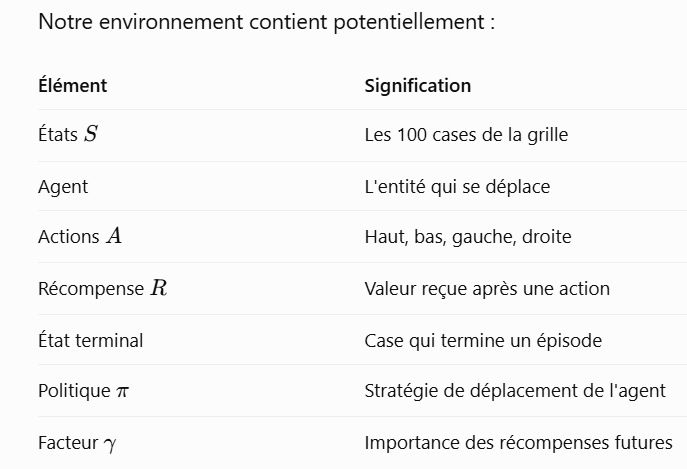

In [1]:
# Bloc 1 : Importation des bibliothèques

import numpy as np                    # Calculs numériques
from matplotlib import pyplot as plt   # Visualisation graphique
from time import sleep                # Pause d'exécution
from IPython.display import clear_output # Actualisation de l'affichage
import math                           # Fonctions mathématiques
import numpy.matlib                   # Manipulation des matrices
import imageio                        # Gestion des images et animations

In [2]:
#@title Utils functions

def plot_pi(pi):
  plt.xticks(np.arange(-1, N+1, 1))
  plt.yticks(np.arange(-1, N+1, 1))
  plt.grid( which='major')

  param = {'lw':3,
           'head_width':2/N}
  for i in range(pi.shape[0]):
    ll = pi[i,:]
    x = i%N
    y = N - math.ceil((i+1)/N)
    args = np.argwhere(ll>0)
    for n in args:
      if n==0:
        plt.arrow(x,y,.5,0,**param)
      elif n==1:
        plt.arrow(x,y,0,.5,**param)
      elif n==2:
        plt.arrow(x,y,-.5,0,**param)
      elif n==3:
        plt.arrow(x,y,0,-.5,**param)

def get_next_Vij(V_2d,i,j):
  if i<0 or i>=N or j<0 or j>=N:
    raise ValueError("indices must be between 0 and N")
  if i==0:
    if j==N-1:
      ll = (-1e3,-1e3,V_2d[i,j-1],V_2d[i+1,j])
    else:
      ll = (V_2d[i,j+1],-1e3,V_2d[i,j-1],V_2d[i+1,j])
  elif j==0:
    if i==N-1:
      ll = (V_2d[i,j+1],V_2d[i-1,j],-1e3,-1e3)
    else:
      ll = (V_2d[i,j+1],V_2d[i-1,j],-1e3,V_2d[i+1,j])
  elif i==N-1:
    ll = (V_2d[i,j+1],V_2d[i-1,j],V_2d[i,j-1],-1e3)
  elif j==N-1:
    ll = (-1e3,V_2d[i-1,j],V_2d[i,j-1],V_2d[i+1,j])
  else:
    ll = (V_2d[i,j+1],V_2d[i-1,j],V_2d[i,j-1],V_2d[i+1,j])
  return ll


def get_Ppi(pi):

  P = np.zeros([N**2,N**2])
  p = 1
  pi = np.array(pi)
  if pi.size == 4:
    pi = np.matlib.repmat(pi,N**2,1)

  for i in range(N):
    for j in range(N):
      s   = i*N+j
      s_E = i*N+j+1
      s_N = (i-1)*N+j
      s_O = i*N+j-1
      s_S = (i+1)*N+j

      # Les probabilités des actions bloquées s'additionnent.
      for a, (di,dj) in enumerate([(0,1),(-1,0),(0,-1),(1,0)]):
        ni, nj = i+di, j+dj
        dest = ni*N+nj if 0 <= ni < N and 0 <= nj < N else s
        P[s,dest] += p*pi[s,a]

  P[0,:] = 0
  P[N**2-1,:]=0

  return P


## Partie 1 : Initialisation

Pour commencer nous allons définir la dynamique du modèle et en particulier la matrice de transition $\mathcal P$ du griddworld ainsi que la matrice de récompense $\mathcal R^\pi \in \mathbb R^{N,N}$ pour une politique de mouvement uniforme avec une probabilité $\pi = 0.25$ constante et récompense constante poour chaque état $r = -1$ sauf pour les états terminaux $(0,0)$ et $(N,N)$ où $r=0$.

In [3]:
N = 10
R = -1*np.ones([N**2,1])
R[0] = 0
R[N**2-1] = 0

Création de la matrice de transition pour une politique de mouvements uniforme avec une probailité $\pi$ = 0.25 et une transition déterministe $p(s' | s, a) = 1$ pour $s'$ situé en $E,N,O$ ou $S$ par rapport à $s$.

**coding task**

Complétez l'mplémentation de la matrice $\mathcal P$ associé à un choix aléatoire parmis les 4 directions $E,N,O$ ou $S$. **Attention** on part du principe que l'agent ne passe pas à travers les bords et une tentative de sorti du griddworld ramène dans le même état (d'où les `if` `else` imbriqués).

In [4]:
P = np.zeros([N**2,N**2])
p = 1
pi = .25

for i in range(N):
  for j in range(N):
    s   = i*N+j
    s_E = i*N+j+1
    s_N = (i-1)*N+j
    s_O = i*N+j-1
    s_S = (i+1)*N+j

    if j < N-1:
      P[s,s_E] = p*pi
    else :
      P[s,s] = p*pi
    if i > 0:
      P[s,s_N] = p*pi
    else :
      P[s,s] = p*pi
    if j > 0:
      P[s,s_O] = p*pi
    else :
      P[s,s] = p*pi
    if i < N-1:
      P[s,s_S] = p*pi
    else :
      P[s,s] = p*pi
    if (i,j)==(0,N-1) or (i,j)==(N-1,0):
      P[s,s] = 2*p*pi

P[0,:] = 0
P[N**2-1,:]=0

#plt.imshow(P)

## Partie 2 : Estimation de la politique et de la valeur des états associée

**Coding Task**: Compléter la fonction suivante permettant d'obtenir la fonction de valeur d'état en implémentant la récursion de Bellman.

In [5]:
def get_V(iter,P,R,gamma,show=1):
  V = np.zeros([N**2,1])
  for n in range(iter):

    V = R + gamma * (P @ V)

    if show and n % 100 == 99:
      clear_output()
      plt.imshow(np.reshape(V,[N,N]))
      plt.title(f'Iteration = {n+1}')
      plt.show()
      sleep(0.1)
  return V

Maintenant que nous avons toutes nos fonctions, nous pouvons calculer la fonction de valeur d'état en itérant sur notre politique $\pi$ :

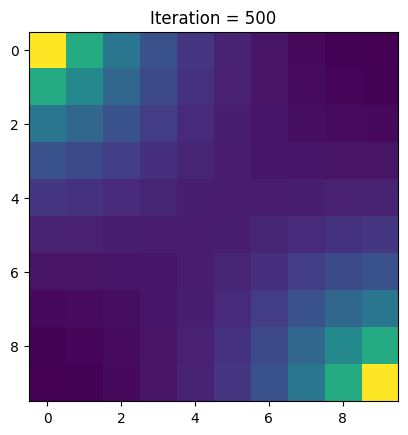

In [6]:
V = np.zeros([N**2,1])
gamma = 1
n_iter = 500

fig = plt.figure()

V = get_V(n_iter,P,R,gamma)


Sans surprise, plus on est proche des points à atteindre, plus la valeur des états est élevée.

**Amélioration de la politique par action gloutonne** : l'évaluation de la fonction de coût associée à notre politique naive nous permet de mettre en évidence une politique $\pi' \geq \pi$. Pour cela il nous faut calculer en tout point quel est le meilleur coup à jouer, c'est à dire la poltique gloutonne ou $greedy$.

**coding task**: Compléter la fonction suivante pour obtenir la greedy policy à partir de la fonction de valeur d'état. La fonction get_next_Vij() renvoie la valeur des états voisins dans un tableau de taille le nombre d'action (donc 4 dans notre cas) avec l'espérance de la valeur d'état après avoir choisi l'action correspondant à l'indice du tableau.

In [7]:
def greedy_policy(V):
  V_2d = np.reshape(V,[N,N])
  pi = np.zeros([N**2,4])

  for i in range(N):
    for j in range(N):
      if i==0 and j==0 or i==N-1 and j==N-1:
          continue
      V_voisin = get_next_Vij(V_2d,i,j)

      args = np.flatnonzero(np.isclose(V_voisin, np.max(V_voisin)))
      pi[i*N+j,args] = 1 / len(args)

  return pi

Nous pouvons enfin afficher la valeur de la politique pour ce griddworld

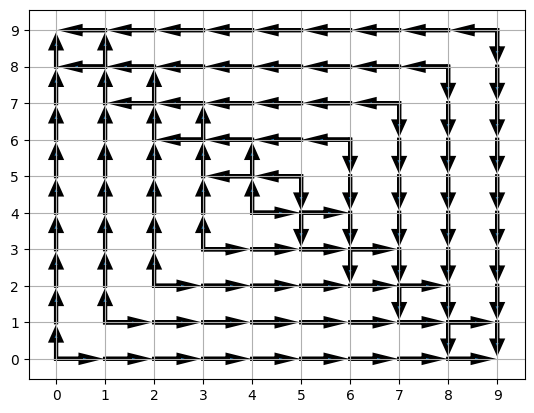

In [8]:
pi = greedy_policy(V)
plot_pi(pi)

## Partie 3 : Maximisation de la politique

Dans le cas précédent, tout l'espace était exploré, conduisant à découvrir la politique optimale après une seule itération. A présent, nous allons initialiser notre politique en faisant le choix d'aller toujours à l'est puis améliorer la politique de façon gloutonne une fois la fonction de valeur estimée.

**coding task** : compléter le code suivant pour permettre d'alterner entre calcul de la fonction de valeur d'état et optimisation de la politique de façon à converger vers la politique idéale.

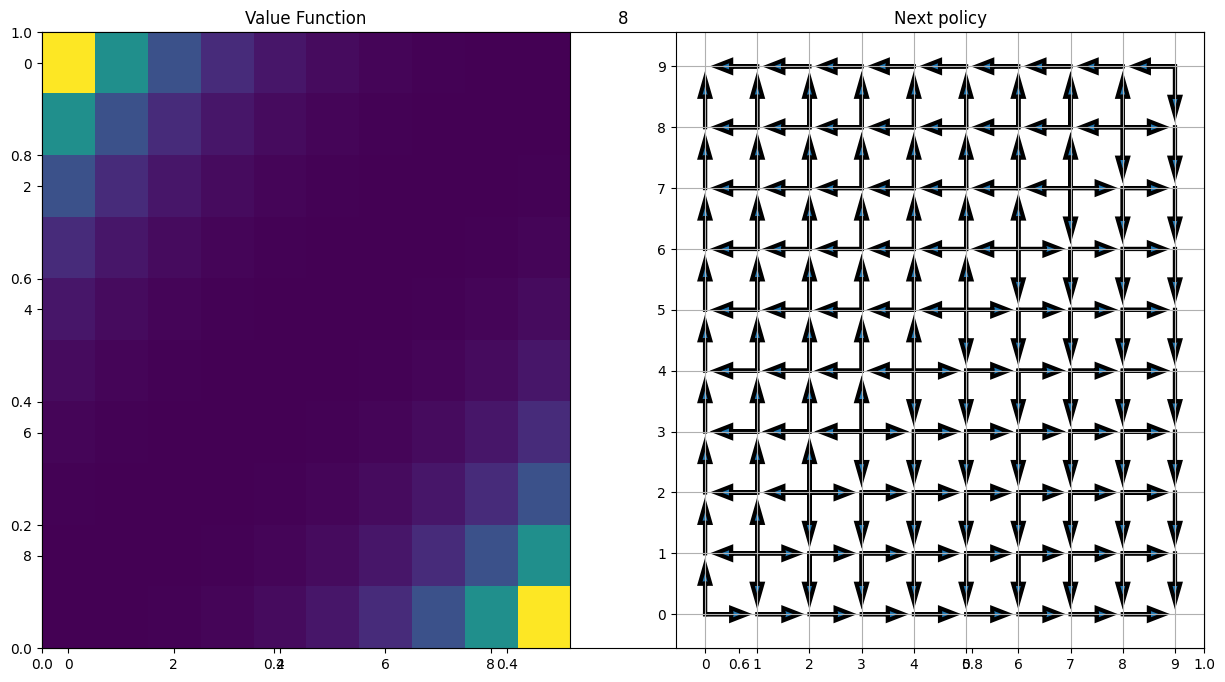

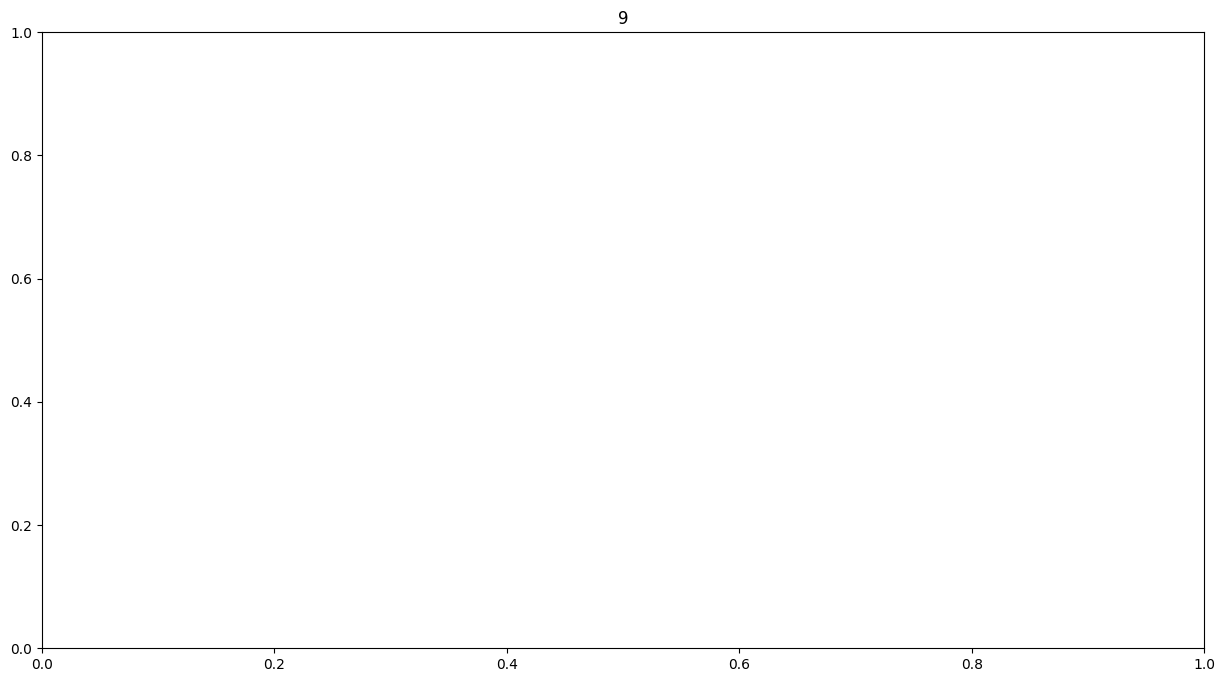

In [9]:
iter_total = 10
iter_policy = 100
show = 1
show_every = 1
gamma = .5

plt.rcParams['figure.figsize'] = [15, 8]

P_pi = get_Ppi([1,0,0,0])


for i in range(iter_total):
  V = get_V(iter_policy, P_pi, R, gamma, show=0)
  pi = greedy_policy(V)
  P_pi = get_Ppi(pi)
  if show and i % show_every == 0:
    clear_output()

    ax = plt.subplot(121)
    plt.imshow(np.reshape(V,[N,N]), aspect="auto")
    ax.set_title('Value Function')
    ax = plt.subplot(122)
    plot_pi(pi)
    ax.set_title('Next policy')
    plt.show()
    plt.title(i)
    sleep(0.1) #Utiliser une valeur plus basse si trop lent

## Partie 4 : Labyrinthe

A présent évaluons la valeur des différents états ainsi que la politique optimale pour un labyrinthe. Le labyrinthe est donné par la matrice suivante :

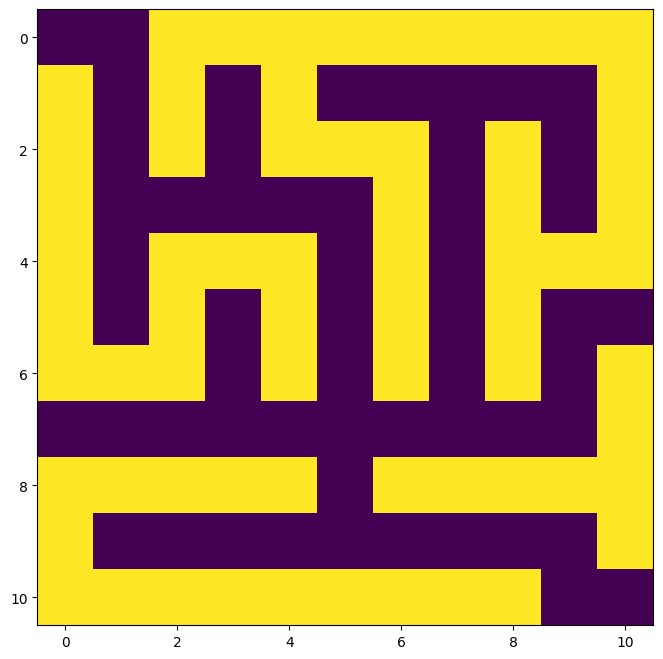

In [10]:
maze =   np.array([[0,0,1,1,1,1,1,1,1,1,1],
                  [1,0,1,0,1,0,0,0,0,0,1],
                  [1,0,1,0,1,1,1,0,1,0,1],
                  [1,0,0,0,0,0,1,0,1,0,1],
                  [1,0,1,1,1,0,1,0,1,1,1],
                  [1,0,1,0,1,0,1,0,1,0,0],
                  [1,1,1,0,1,0,1,0,1,0,1],
                  [0,0,0,0,0,0,0,0,0,0,1],
                  [1,1,1,1,1,0,1,1,1,1,1],
                  [1,0,0,0,0,0,0,0,0,0,1],
                  [1,1,1,1,1,1,1,1,1,0,0]])

plt.imshow(maze)

**À vous de jouer !**

À vous de réécrire les matrices de transition et de récompense pour ce nouveau problème.

### Solution du labyrinthe

Les cases 0 sont accessibles et les cases 1 sont des murs. On choisit comme états terminaux les deux extrémités (0,0) et (10,10), par analogie avec le Gridworld. Chaque déplacement coûte −1 sauf dans les états terminaux et les murs (non accessibles). Une action bloquée laisse l’agent dans son état. Les lignes des états terminaux et des murs sont nulles, selon la convention du TP.

In [11]:
H, W = maze.shape
S = H * W
terminals = {0, S-1}
free = np.flatnonzero(maze.ravel() == 0)
R_maze = np.zeros((S, 1))
for s in free:
    if s not in terminals:
        R_maze[s] = -1

actions = [(0,1), (-1,0), (0,-1), (1,0)]

def next_state_maze(s, a):
    i, j = divmod(s, W)
    di, dj = actions[a]
    ni, nj = i+di, j+dj
    if 0 <= ni < H and 0 <= nj < W and maze[ni,nj] == 0:
        return ni*W+nj
    return s

def get_P_maze(pi):
    P = np.zeros((S,S))
    for s in free:
        if s in terminals:
            continue
        for a in range(4):
            P[s,next_state_maze(s,a)] += pi[s,a]
    return P

pi_maze = np.zeros((S,4))
for s in free:
    if s not in terminals:
        pi_maze[s] = 0.25
P_maze = get_P_maze(pi_maze)
print('Dimensions :', P_maze.shape, R_maze.shape)
assert all(np.isclose(P_maze[s].sum(), 1) for s in free if s not in terminals)

Dimensions : (121, 121) (121, 1)


In [12]:
# Évaluation et amélioration successives de la politique
# gamma < 1 garantit la convergence de l'évaluation même pour une politique bloquée.
gamma_maze = 0.95
for k in range(100):
    P_maze = get_P_maze(pi_maze)
    V_maze = np.zeros((S,1))
    for t in range(2000):
        new_V = R_maze + gamma_maze * (P_maze @ V_maze)
        if np.max(np.abs(new_V-V_maze)) < 1e-10:
            V_maze = new_V
            break
        V_maze = new_V
    new_pi = np.zeros_like(pi_maze)
    for s in free:
        if s in terminals:
            continue
        q = np.array([-1 + gamma_maze*V_maze[next_state_maze(s,a),0] for a in range(4)])
        best = np.flatnonzero(np.isclose(q, q.max(), atol=1e-10, rtol=1e-10))
        new_pi[s,best] = 1/len(best)
    if np.array_equal(new_pi, pi_maze):
        print('Politique stable après', k+1, 'itérations')
        break
    pi_maze = new_pi
P_maze = get_P_maze(pi_maze)

Politique stable après 3 itérations


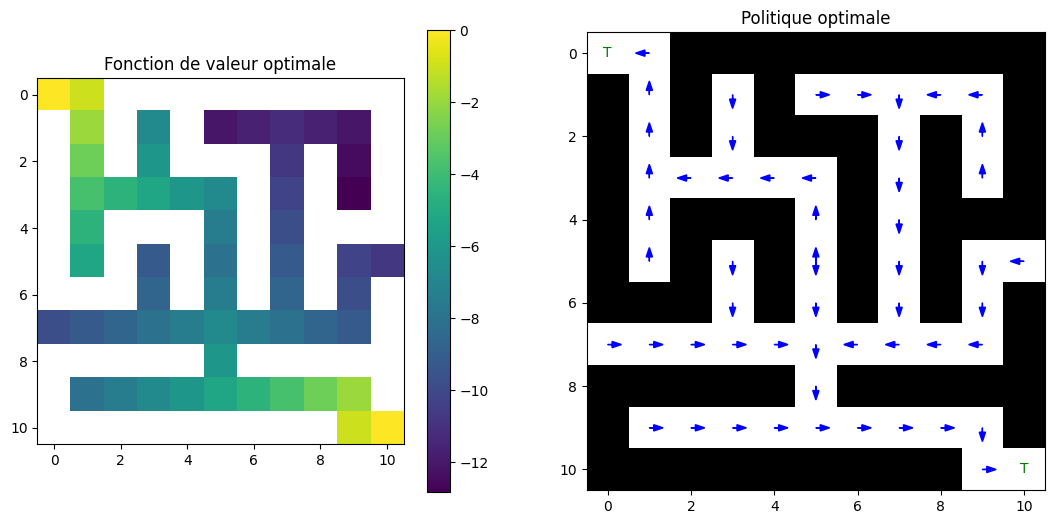

In [13]:
# Visualisation de la fonction de valeur et de la politique
fig, axes = plt.subplots(1,2,figsize=(13,6))
values = np.ma.masked_where(maze == 1, V_maze.reshape(H,W))
im = axes[0].imshow(values, cmap='viridis')
fig.colorbar(im, ax=axes[0])
axes[0].set_title('Fonction de valeur optimale')
axes[1].imshow(maze, cmap='Greys', vmin=0,vmax=1)
for s in free:
    i,j = divmod(s,W)
    if s in terminals:
        axes[1].text(j,i,'T',ha='center',va='center',color='green')
    else:
        for a in np.flatnonzero(pi_maze[s]):
            di,dj = actions[a]
            axes[1].arrow(j,i,0.33*dj,0.33*di,head_width=0.15,color='blue',length_includes_head=True)
axes[1].set_title('Politique optimale')
plt.show()